# 1.2M-Parameter CNN for CIFAR-10 (PyTorch)

**Author:** Vishwajeet Adkine

A compact VGG-style convolutional network with **about 1.2 million parameters**, trained from scratch on CIFAR-10 (60,000 32×32 colour images, 10 classes).

**Recipe**
- 6 conv layers in 3 blocks (64 → 128 → 256 channels) with BatchNorm and ReLU, max-pooling between blocks
- Global average pooling, then a small classifier head (256 → 192 → 10) with dropout
- Data augmentation: random crop (padding 4) and horizontal flip
- SGD + Nesterov momentum, one-cycle learning-rate schedule, weight decay, label smoothing, mixed precision

**Before running:** Runtime → Change runtime type → **T4 GPU**.

**Contents:** 1 Setup · 2 Data · 3 Model · 4 Training · 5 Curves · 6 Test evaluation · 7 Error analysis · 8 Visualising filters · 9 Predict your own image · 10 Save

## 1. Setup

In [1]:
import time, copy, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"

# ---------------- configuration (edit here) ----------------
EPOCHS        = 30
BATCH_SIZE    = 128
MAX_LR        = 0.1
WEIGHT_DECAY  = 5e-4
MOMENTUM      = 0.9
LABEL_SMOOTH  = 0.1
DROPOUT       = 0.3
VAL_SIZE      = 5000
# -----------------------------------------------------------

print("PyTorch", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Training will be very slow. Enable a GPU runtime.")

PyTorch 2.14.1+cu130 | device: cuda
Tesla T4


## 2. Data

CIFAR-10 is downloaded automatically. We hold out 5,000 training images for validation (using the *test-time* transform, with no augmentation) and keep the official 10,000 test images untouched until the end.

In [2]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf  = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_full = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=train_tf)
val_full   = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=eval_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=eval_tf)

perm = np.random.RandomState(SEED).permutation(len(train_full))
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]
train_set = Subset(train_full, train_idx)
val_set   = Subset(val_full, val_idx)

loader_kw = dict(num_workers=2, pin_memory=(DEVICE == "cuda"))
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  drop_last=True, **loader_kw)
val_loader   = DataLoader(val_set,   batch_size=512, shuffle=False, **loader_kw)
test_loader  = DataLoader(test_set,  batch_size=512, shuffle=False, **loader_kw)

print(f"train {len(train_set)} | val {len(val_set)} | test {len(test_set)}")

100%|██████████| 170M/170M [14:57<00:00, 190kB/s]


train 45000 | val 5000 | test 10000


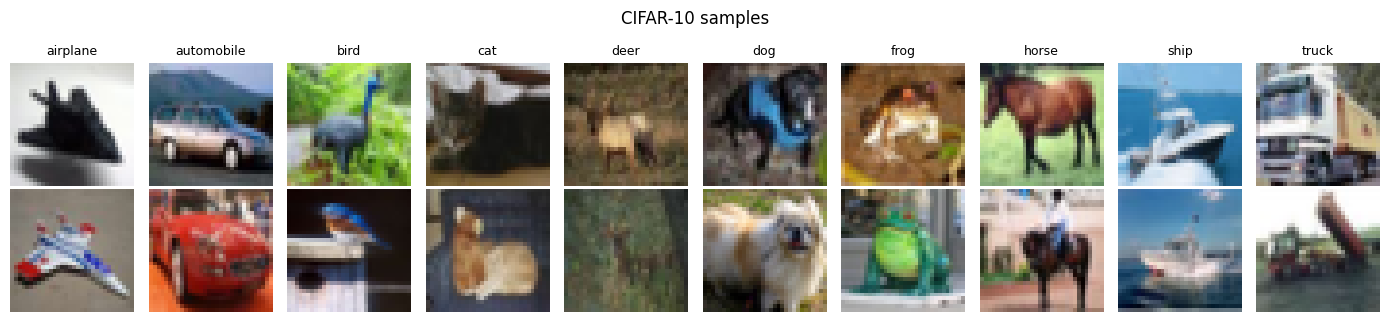

In [3]:
def denorm(x):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (x.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

raw = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=T.ToTensor())
fig, axes = plt.subplots(2, 10, figsize=(14, 3.3))
for c in range(10):
    imgs = [i for i, y in enumerate(raw.targets[:5000]) if y == c][:2]
    for r, i in enumerate(imgs):
        axes[r, c].imshow(raw[i][0].permute(1, 2, 0).numpy()); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle("CIFAR-10 samples"); plt.tight_layout(); plt.show()

## 3. Model

```
Input 3x32x32
Block 1: Conv(3->64)   BN ReLU  Conv(64->64)    BN ReLU  MaxPool   -> 64 x16x16
Block 2: Conv(64->128) BN ReLU  Conv(128->128)  BN ReLU  MaxPool   -> 128x 8x 8
Block 3: Conv(128->256) BN ReLU Conv(256->256)  BN ReLU  MaxPool   -> 256x 4x 4
Global average pool -> 256
Linear(256->192) ReLU Dropout  Linear(192->10)
```

All convolutions are 3×3 with `bias=False` (BatchNorm supplies the shift). The notebook asserts that the parameter count is within 1.15M to 1.25M.

In [4]:
def conv_bn_relu(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

class CifarCNN(nn.Module):
    def __init__(self, num_classes=10, dropout=DROPOUT):
        super().__init__()
        self.features = nn.Sequential(
            *conv_bn_relu(3, 64),    *conv_bn_relu(64, 64),    nn.MaxPool2d(2),
            *conv_bn_relu(64, 128),  *conv_bn_relu(128, 128),  nn.MaxPool2d(2),
            *conv_bn_relu(128, 256), *conv_bn_relu(256, 256),  nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256, 192), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(192, num_classes),
        )
        for m in self.modules():                       # He initialisation for conv layers
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

model = CifarCNN().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
n_train  = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters    : {n_params:,}")
print(f"Trainable parameters: {n_train:,}")
assert 1_150_000 <= n_params <= 1_250_000, "parameter count drifted away from ~1.2M"

print()
for name, p in model.named_parameters():
    if p.ndim > 1:
        print(f"{name:32s} {str(tuple(p.shape)):22s} {p.numel():>9,}")

Total parameters    : 1,197,578
Trainable parameters: 1,197,578

features.0.weight                (64, 3, 3, 3)              1,728
features.3.weight                (64, 64, 3, 3)            36,864
features.7.weight                (128, 64, 3, 3)           73,728
features.10.weight               (128, 128, 3, 3)         147,456
features.14.weight               (256, 128, 3, 3)         294,912
features.17.weight               (256, 256, 3, 3)         589,824
classifier.1.weight              (192, 256)                49,152
classifier.4.weight              (10, 192)                  1,920


## 4. Training

One-cycle learning-rate schedule (warm-up to `MAX_LR`, then cosine-style decay), stepped every batch. The best epoch by validation accuracy is kept.

In [5]:
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
optimizer = torch.optim.SGD(model.parameters(), lr=MAX_LR, momentum=MOMENTUM,
                            weight_decay=WEIGHT_DECAY, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=len(train_loader), pct_start=0.2)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
                scheduler.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

In [6]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
best_acc, best_state = 0.0, None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc, optimizer.param_groups[0]["lr"])):
        history[k].append(v)
    if va_acc > best_acc:
        best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}/{EPOCHS} | loss {tr_loss:.3f} | acc {tr_acc:.4f} | "
          f"val_loss {va_loss:.3f} | val_acc {va_acc:.4f} | {time.time() - t0:.0f}s"
          + ("  *best*" if va_acc == best_acc else ""))

print(f"\nTraining time: {(time.time() - start) / 60:.1f} min | best val acc: {best_acc:.4f}")
model.load_state_dict(best_state)

Epoch  1/30 | loss 1.822 | acc 0.3665 | val_loss 1.566 | val_acc 0.5072 | 20s  *best*
Epoch  2/30 | loss 1.450 | acc 0.5743 | val_loss 1.566 | val_acc 0.5382 | 17s  *best*
Epoch  3/30 | loss 1.276 | acc 0.6583 | val_loss 1.328 | val_acc 0.6444 | 16s  *best*
Epoch  4/30 | loss 1.162 | acc 0.7193 | val_loss 1.315 | val_acc 0.6394 | 16s
Epoch  5/30 | loss 1.084 | acc 0.7559 | val_loss 1.119 | val_acc 0.7356 | 17s  *best*
Epoch  6/30 | loss 1.022 | acc 0.7863 | val_loss 1.150 | val_acc 0.7344 | 18s
Epoch  7/30 | loss 0.974 | acc 0.8071 | val_loss 1.005 | val_acc 0.7874 | 17s  *best*
Epoch  8/30 | loss 0.939 | acc 0.8229 | val_loss 1.056 | val_acc 0.7654 | 16s
Epoch  9/30 | loss 0.907 | acc 0.8385 | val_loss 0.963 | val_acc 0.8112 | 17s  *best*
Epoch 10/30 | loss 0.887 | acc 0.8451 | val_loss 0.989 | val_acc 0.7952 | 17s
Epoch 11/30 | loss 0.870 | acc 0.8547 | val_loss 0.923 | val_acc 0.8254 | 17s  *best*
Epoch 12/30 | loss 0.851 | acc 0.8627 | val_loss 1.048 | val_acc 0.7632 | 17s
Epoch 13

<All keys matched successfully>

## 5. Training curves

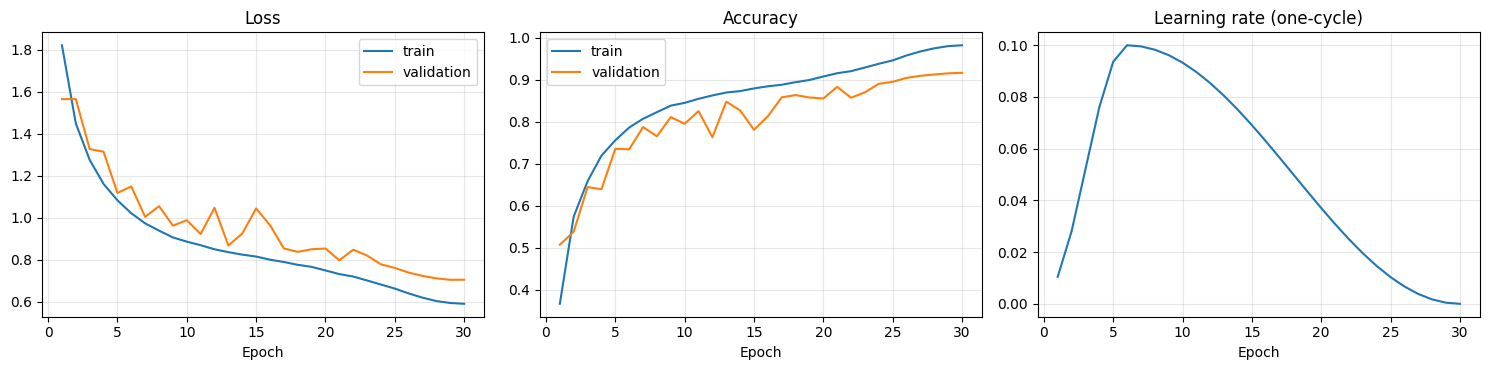

In [7]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(ep, history["train_loss"], label="train"); ax[0].plot(ep, history["val_loss"], label="validation")
ax[0].set(title="Loss", xlabel="Epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, history["train_acc"], label="train"); ax[1].plot(ep, history["val_acc"], label="validation")
ax[1].set(title="Accuracy", xlabel="Epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].plot(ep, history["lr"]); ax[2].set(title="Learning rate (one-cycle)", xlabel="Epoch"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Test-set evaluation

In [8]:
@torch.no_grad()
def predict_all(loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits.append(model(x.to(DEVICE)).float().cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels)

logits, labels = predict_all(test_loader)
probs = F.softmax(logits, dim=1)
preds = probs.argmax(1)
test_acc = (preds == labels).float().mean().item()
top3 = (logits.topk(3, dim=1).indices == labels[:, None]).any(1).float().mean().item()
print(f"Test accuracy : {test_acc * 100:.2f}%")
print(f"Top-3 accuracy: {top3 * 100:.2f}%\n")
print(classification_report(labels, preds, target_names=CLASSES, digits=3))

Test accuracy : 92.23%
Top-3 accuracy: 98.77%

              precision    recall  f1-score   support

    airplane      0.912     0.949     0.930      1000
  automobile      0.949     0.972     0.960      1000
        bird      0.915     0.880     0.897      1000
         cat      0.837     0.838     0.838      1000
        deer      0.925     0.938     0.931      1000
         dog      0.878     0.869     0.873      1000
        frog      0.935     0.939     0.937      1000
       horse      0.965     0.940     0.952      1000
        ship      0.958     0.951     0.954      1000
       truck      0.950     0.947     0.948      1000

    accuracy                          0.922     10000
   macro avg      0.922     0.922     0.922     10000
weighted avg      0.922     0.922     0.922     10000



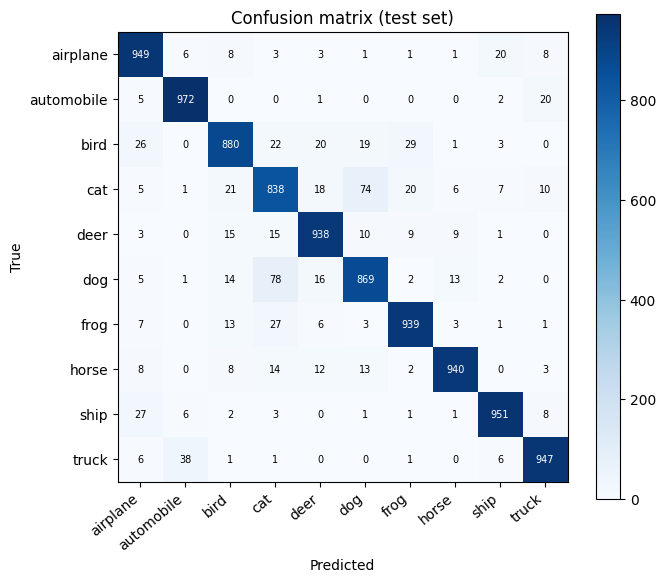

Most confused pairs (true -> predicted):
  dog        -> cat        : 78
  cat        -> dog        : 74
  truck      -> automobile : 38
  bird       -> frog       : 29
  ship       -> airplane   : 27


In [9]:
cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(10), yticks=range(10), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel="Predicted", ylabel="True", title="Confusion matrix (test set)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
print("Most confused pairs (true -> predicted):")
for idx in np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]:
    print(f"  {CLASSES[idx[0]]:10s} -> {CLASSES[idx[1]]:10s} : {off[idx[0], idx[1]]}")

## 7. Error analysis

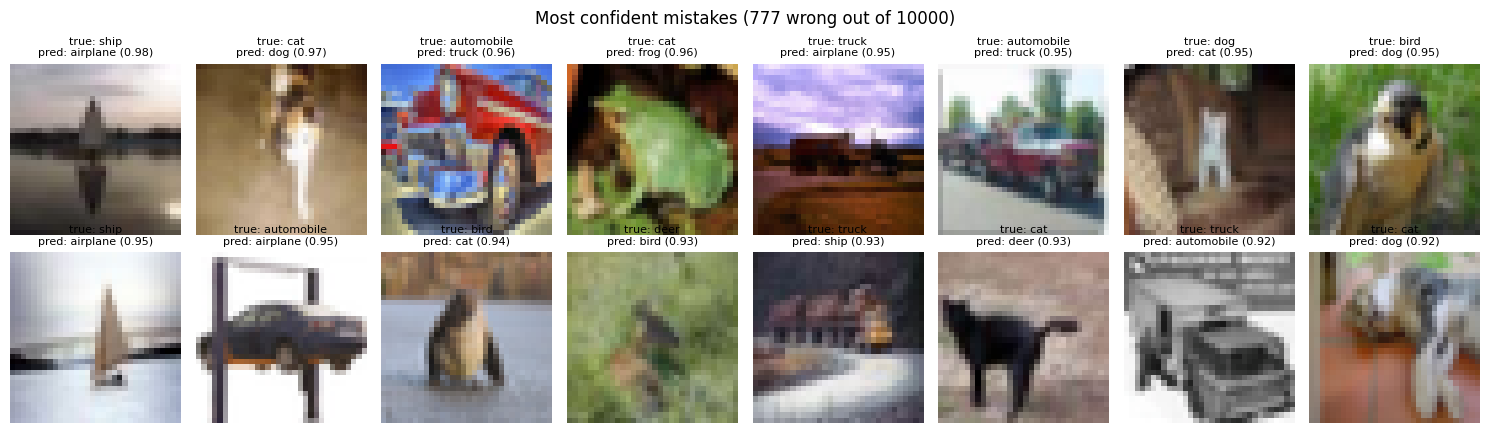

In [10]:
wrong = (preds != labels).nonzero().squeeze(1)
conf = probs[wrong].max(1).values
order = wrong[conf.argsort(descending=True)][:16]          # most confident mistakes

fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for ax, k in zip(axes.ravel(), order):
    img, _ = test_set[int(k)]
    ax.imshow(denorm(img)); ax.axis("off")
    ax.set_title(f"true: {CLASSES[labels[k]]}\npred: {CLASSES[preds[k]]} ({probs[k].max():.2f})", fontsize=8)
plt.suptitle(f"Most confident mistakes ({len(wrong)} wrong out of {len(labels)})")
plt.tight_layout(); plt.show()

## 8. Visualising what the network learned

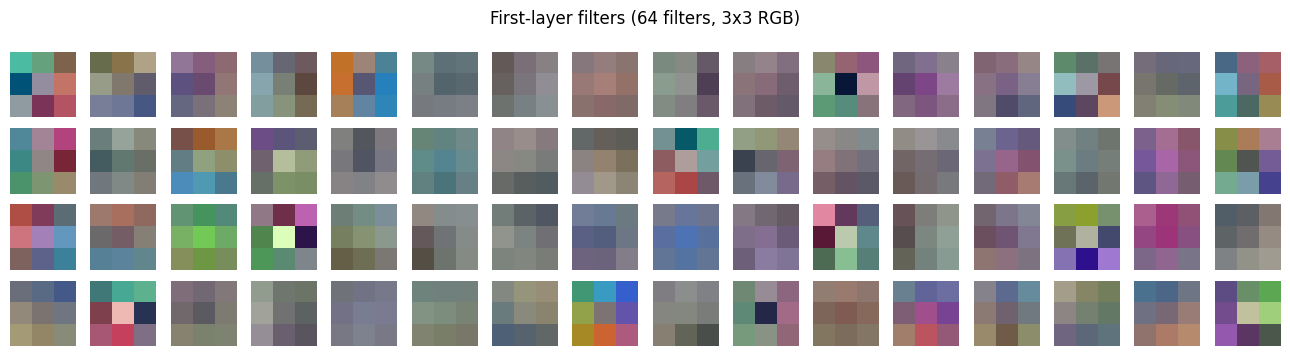

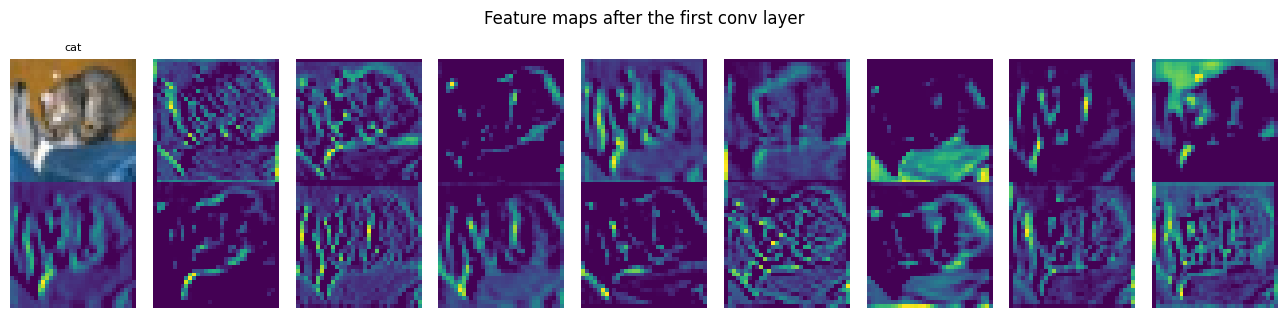

In [11]:
w = model.features[0].weight.detach().cpu()               # first conv layer: 64 x 3 x 3 x 3
w = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(4, 16, figsize=(13, 3.6))
for ax, f in zip(axes.ravel(), w):
    ax.imshow(f.permute(1, 2, 0).numpy(), interpolation="nearest"); ax.axis("off")
plt.suptitle("First-layer filters (64 filters, 3x3 RGB)"); plt.tight_layout(); plt.show()

# feature maps after the first conv-BN-ReLU for one test image
img, lab = test_set[0]
with torch.no_grad():
    fmap = model.features[:3](img.unsqueeze(0).to(DEVICE)).cpu()[0]
fig, axes = plt.subplots(2, 9, figsize=(13, 3.2))
axes[0, 0].imshow(denorm(img)); axes[0, 0].set_title(CLASSES[lab], fontsize=8)
for ax in axes.ravel(): ax.axis("off")
for ax, m in zip(axes.ravel()[1:], fmap[:17]):
    ax.imshow(m.numpy(), cmap="viridis")
plt.suptitle("Feature maps after the first conv layer"); plt.tight_layout(); plt.show()

## 9. Predict your own image

Run the first cell and upload a photo, then run the second. The image is squashed to 32×32, so use a clear single object (an animal, a vehicle, a ship...). Expect weaker results than on test images, because the network has only seen CIFAR-style pictures.

In [14]:
from google.colab import files
uploaded = files.upload()

Saving test 2.jpg to test 2.jpg


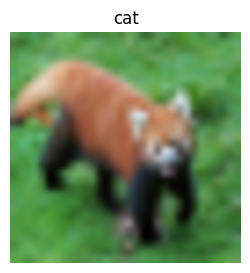

cat           53.4%
dog           32.8%
deer           3.1%


In [15]:
from PIL import Image

def predict_image(path, top_k=3):
    img = Image.open(path).convert("RGB").resize((32, 32), Image.BILINEAR)
    x = eval_tf(img).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        p = F.softmax(model(x).float(), dim=1)[0].cpu()
    top = p.topk(top_k)
    plt.figure(figsize=(3, 3)); plt.imshow(img.resize((128, 128))); plt.axis("off")
    plt.title(CLASSES[int(top.indices[0])]); plt.show()
    for s, i in zip(top.values, top.indices):
        print(f"{CLASSES[int(i)]:12s} {float(s) * 100:5.1f}%")

for fname in uploaded:
    predict_image(fname)

## 10. Save the model

In [16]:
torch.save({"state_dict": model.state_dict(), "classes": CLASSES, "mean": MEAN, "std": STD,
            "test_acc": test_acc, "n_params": n_params}, "cifar_cnn.pt")
print("Saved cifar_cnn.pt")

# To reload later:
#   ckpt = torch.load("cifar_cnn.pt", map_location="cpu")
#   model = CifarCNN(); model.load_state_dict(ckpt["state_dict"]); model.eval()
# To download from Colab:
#   from google.colab import files; files.download("cifar_cnn.pt")

Saved cifar_cnn.pt


## Summary and next steps

- Trained a ~1.2M-parameter CNN from scratch with augmentation, BatchNorm, one-cycle SGD and label smoothing.
- Evaluated on the untouched test set with a confusion matrix, per-class metrics and a look at the most confident mistakes.
- **Ideas:** ablations (remove augmentation, BatchNorm or label smoothing), CutMix/MixUp, residual connections, more epochs, test-time augmentation (flip), compare against a ResNet-18 baseline, or export to ONNX.